# L5 — Représentation en graphe et GNN

**Objectif.** Représenter chaque scénario par un graphe hétérogène flux / lien, entraîner un réseau à passage de
messages qui prédit log10(délai) par flux, et mesurer **honnêtement** ce que le graphe apporte, à l'aide de deux
contrôles : le même réseau sans passage de messages (`gnn_k0`) et un MLP plat sur les mêmes informations
résumées à la main (`mlp_flat`).

Explication rédigée : `docs/explications/05_gnn.md`. Décisions : `JOURNAL.md` (D3.1 à D3.8).

In [1]:
import pandas as pd
import torch

from src.config import RESULTS_DIR
from src.eda import fig_learning_curves
from src.graphs import EXAMPLE_SCENARIO, fig_example_graph, load_graphs, FLOW_FEATS, LINK_FEATS, EDGE_FEATS
from src.models.gnn import FlowLinkGNN
from src.plotting import set_style, savefig

set_style()
pd.set_option("display.width", 200)

C:\Users\bourh\Desktop\AI-Based Dynamic Resource Allocation for B5G Network Slicing\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. Le graphe d'un scénario

**Nœuds flux** : type de slice (one-hot), δ, ratio de provisionnement, débit, taille de paquet, longueur du chemin.
**Nœuds lien** (un par lien utilisé par au moins un flux) : capacité, ρ, nombre de flux, nombre de files, M/M/1/K
du lien, type accès / cœur / sortie.
**Arêtes** : une par *saut* (flux qui traverse un lien), dans les deux sens. Leurs attributs sont ce qui appartient
au **couple** (flux, lien) : position relative sur le chemin, part WFQ, ρ de la file, file par défaut, nombre de
flux dans la file, M/M/1/K de la file.

La part WFQ est sur l'arête et non sur un nœud : sur un même lien, deux flux de slices différentes ont des parts
garanties différentes, et un même flux change de part d'un lien à l'autre.

In [2]:
print("features des nœuds flux :", FLOW_FEATS)
print("features des nœuds lien :", LINK_FEATS)
print("features des arêtes     :", EDGE_FEATS)

val = load_graphs("val")
g = val[0]
print(f"\nexemple ({len(val)} graphes dans val) — scénario {g.scenario_id}")
print(g)

features des nœuds flux : ['is_eMBB', 'is_URLLC', 'is_mMTC', 'delta', 'prov_ratio', 'log_rate', 'log_pkt_size', 'path_len']
features des nœuds lien : ['log_capacity', 'rho_link', 'log_n_flows_link', 'log_levels_qos', 'log_n_queues_used', 'log_mm1k_link', 'is_access', 'is_core', 'is_egress']
features des arêtes     : ['hop_rel', 'log_wfq_share', 'log_rho_queue', 'is_default_queue', 'log_n_flows_queue', 'log_mm1k_queue']



exemple (907 graphes dans val) — scénario 7
HeteroData(
  scenario_id=7,
  flow={
    x=[106, 8],
    y=[106],
    y_mask=[106],
    flow_id=[106],
  },
  link={ x=[128, 9] },
  (flow, traverses, link)={
    edge_index=[2, 526],
    edge_attr=[526, 6],
  },
  (link, carries, flow)={
    edge_index=[2, 526],
    edge_attr=[526, 6],
  }
)


### Figure : les deux vues d'un même scénario

À gauche le réseau, à droite le graphe biparti que voit le GNN. Les deux panneaux partagent la même échelle de
couleur pour ρ, et les liens saturés (ρ ≥ 1) sont entourés de rouge.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


figure -> C:\Users\bourh\Desktop\AI-Based Dynamic Resource Allocation for B5G Network Slicing\reports\figures\L5_01_exemple_graphe.png


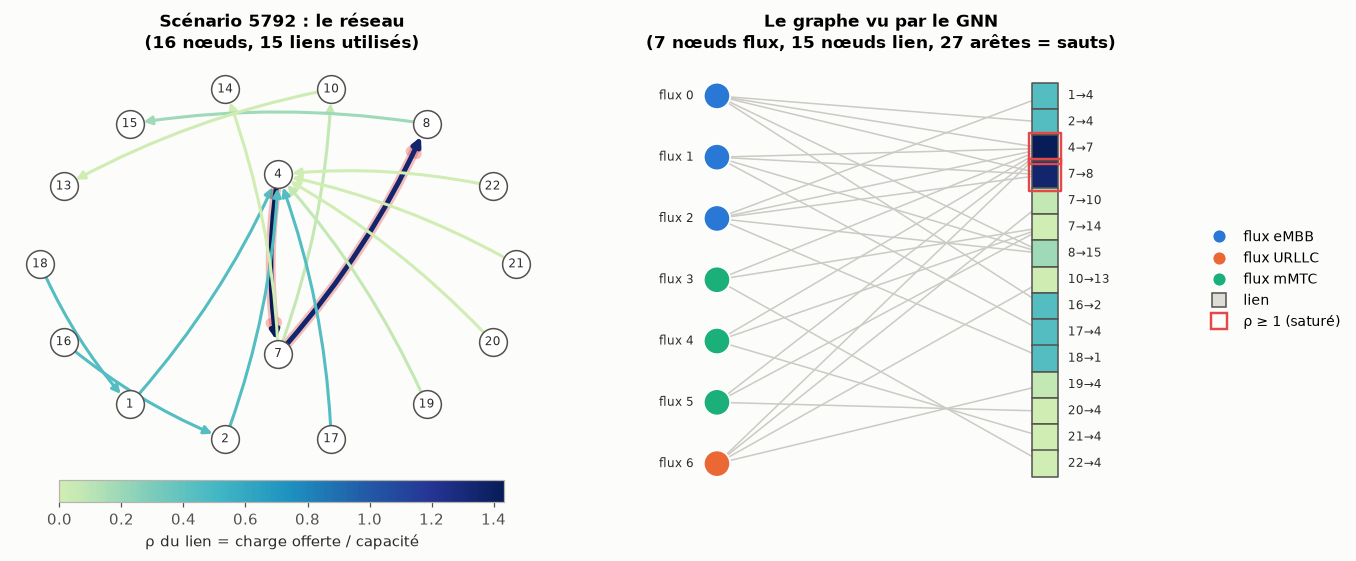

In [3]:
fig = fig_example_graph(EXAMPLE_SCENARIO)
print("figure ->", savefig(fig, "L5_01_exemple_graphe"))

Le scénario 5792 (train) est choisi parce qu'il est lisible (7 flux, 15 liens, 27 sauts), contient les 3 types de
slice, et que **ses 7 flux traversent le même lien saturé 4→7**. C'est exactement le couplage qu'un vecteur plat
par flux ne peut représenter qu'à travers des résumés choisis à la main.

## 2. Le modèle

Pour k = 1 … K :

1. **les liens écoutent les flux qu'ils transportent**
   `h_l ← LayerNorm( h_l + Dropout(ReLU( CONV_{f→l}( {h_f, e_fl}, h_l ) )) )`
2. **les flux écoutent les liens de leur chemin** (déjà mis à jour)
   `h_f ← LayerNorm( h_f + Dropout(ReLU( CONV_{l→f}( {h_l, e_fl}, h_f ) )) )`

puis la lecture `délai_f = MLP(h_f)` en log10 des secondes.

Deux convolutions sont implémentées :
- **GATv2Conv** avec `edge_dim` : `Σ_j α_ij W h_j`, l'attention `α_ij` étant apprise depuis `(h_dst, h_j, e_ij)`.
  Le lien peut donc pondérer différemment un gros flux eMBB et un petit mMTC, et les poids sont inspectables.
- **EdgeSAGE** : `W_root h_dst + moyenne_j ReLU(W_msg [h_j ‖ e_ij])`. `SAGEConv` standard ignore les attributs
  d'arête, ce qui ferait disparaître la part WFQ : on a donc réécrit le message.

**Pourquoi pas GCN.** Il suppose un graphe homogène et pondère les voisins par leur seul degré (1/√(d_i·d_j)) :
il ne distingue pas un nœud flux d'un nœud lien et ne peut pas lire un attribut d'arête.

In [4]:
dims = (g["flow"].x.size(1), g["link"].x.size(1), g["flow", "traverses", "link"].edge_attr.size(1))
for conv, layers in (("gatv2", 3), ("sage", 3), ("sage", 0)):
    m = FlowLinkGNN(*dims, conv=conv, hidden=128, layers=layers, heads=4, dropout=0.1)
    n = sum(p.numel() for p in m.parameters())
    print(f"conv={conv:6s} K={layers} -> {n:>9,} paramètres")

with torch.no_grad():                      # une passe avant sur 4 graphes, pour vérifier la forme de sortie
    from torch_geometric.loader import DataLoader
    batch = next(iter(DataLoader(val[:4], batch_size=4)))
    out = FlowLinkGNN(*dims, conv="gatv2", hidden=128, layers=3)(batch)
print(f"\nlot de 4 graphes : {batch['flow'].num_nodes} flux -> sortie {tuple(out.shape)}")

conv=gatv2  K=3 ->   868,481 paramètres
conv=sage   K=3 ->   256,385 paramètres
conv=sage   K=0 ->    52,097 paramètres

lot de 4 graphes : 429 flux -> sortie (429,)


Avec **K = 0** les deux boucles ne s'exécutent jamais : il ne reste que `MLP_lecture(MLP_flux(x_f))`, un MLP sur
les seules variables du flux. C'est le modèle `gnn_k0`, et c'est la raison pour laquelle il faut l'interpréter
avec prudence (section 4).

## 3. Entraînement et contrôle du surapprentissage

`python -m src.train_gnn --model gnn_gatv2 --seed 0` : MSE sur log10(délai), AdamW (lr 1e-3, weight decay 1e-5),
`ReduceLROnPlateau`, arrêt précoce sur la **MAE_log de val**, lots de 32 graphes. Le test n'est prédit qu'une
seule fois, à la fin, avec le meilleur checkpoint.

76 époques, meilleure époque 61, val MAE_log 0.1282, 141 min au total (103 s par époque)


figure -> C:\Users\bourh\Desktop\AI-Based Dynamic Resource Allocation for B5G Network Slicing\reports\figures\L5_02_courbes_apprentissage.png


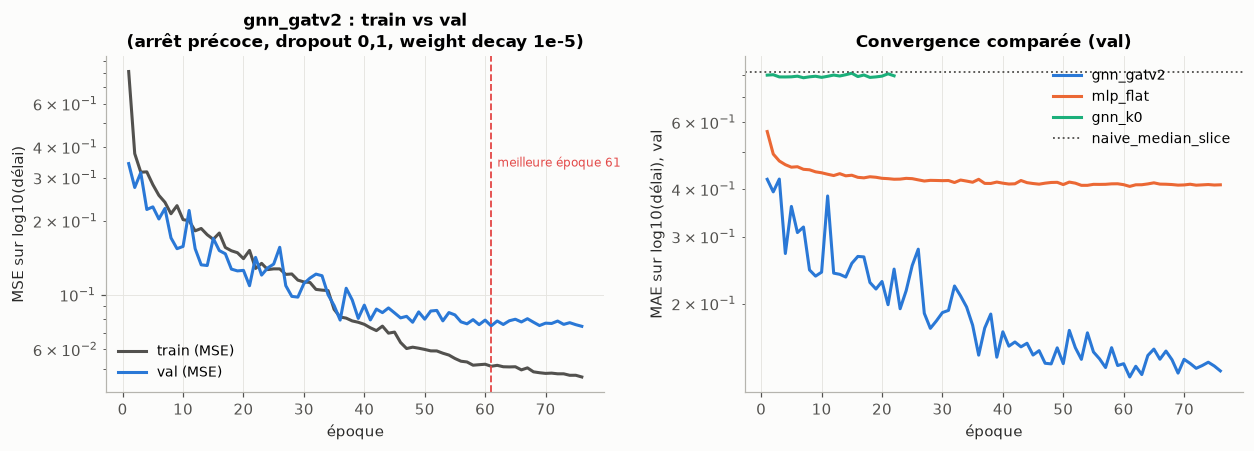

In [5]:
log = pd.read_csv(RESULTS_DIR / "train_logs" / "gnn_gatv2__seed0.csv")
best = int(log.val_mae_log.idxmin()) + 1
print(f"{len(log)} époques, meilleure époque {best}, val MAE_log {log.val_mae_log.min():.4f}, "
      f"{log.seconds.sum()/60:.0f} min au total ({log.seconds.median():.0f} s par époque)")

fig = fig_learning_curves()
print("figure ->", savefig(fig, "L5_02_courbes_apprentissage"))

Train et val descendent ensemble jusqu'à l'époque ~36 ; ensuite val plafonne pendant que train continue à
descendre. L'écart reste faible (0,075 contre 0,05 de MSE) et l'arrêt précoce tranche à l'époque 61 : le
surapprentissage est visible mais contrôlé (dropout 0,1, weight decay 1e-5, arrêt précoce).

**Limite assumée.** Pas de recherche d'hyperparamètres : une exécution complète coûte 2,4 h, la grille prévue en
coûterait 30 à 60 (JOURNAL D3.8). On garde la configuration initiale et on la défend par ces courbes.

## 4. Résultats et lecture des deux ablations

In [6]:
m = pd.read_csv(RESULTS_DIR / "metrics_all.csv")
m = m[(m.subset == "all") & (m.slice_type == "ALL")]
table = m.pivot_table(index="model", columns="split", values="mae_log", aggfunc="mean")
table = table[["val", "test", "test_unseen_topo"]].sort_values("test", ascending=False)
table["graines"] = m.groupby("model").seed.nunique()          # moyenne sur combien d'exécutions
std = m[m.split == "test"].groupby("model").mae_log.std()      # écart-type entre graines (NaN si une seule)
table["écart-type (test)"] = std
print("MAE sur log10(délai) :")
print(table.round(3).to_string())

print("\nMAE par type de slice (test) :")
slices = pd.read_csv(RESULTS_DIR / "metrics_all.csv")
slices = slices[(slices.split == "test") & (slices.subset == "all") & (slices.slice_type != "ALL")]
print(slices.pivot_table(index="model", columns="slice_type", values="mae_log", aggfunc="mean").round(3).to_string())

MAE sur log10(délai) :
split                 val   test  test_unseen_topo  graines  écart-type (test)
model                                                                         
naive_median_slice  0.815  0.822             0.790        1                NaN
gnn_k0              0.785  0.792             0.735        1                NaN
mlp_flat            0.407  0.403             0.372        3              0.002
gnn_gatv2           0.128  0.128             0.115        1                NaN

MAE par type de slice (test) :
slice_type          URLLC   eMBB   mMTC
model                                  
gnn_gatv2           0.140  0.176  0.122
gnn_k0              0.692  0.699  0.825
mlp_flat            0.420  0.504  0.393
naive_median_slice  0.765  0.703  0.845


**Le piège.** `gnn_k0` (0,792) est à peine meilleur que la baseline naïve (0,822), mais ce n'est **pas** la mesure
de l'apport du passage de messages : avec K = 0 les nœuds lien et les attributs de saut sont déconnectés de la
lecture, donc le modèle ne voit ni ρ, ni capacité, ni part WFQ, ni terme de file. Il faut lire les deux ablations
ensemble :

- **0,792 → 0,401** (`gnn_k0` → `mlp_flat`) : ce que récupèrent les **agrégats calculés à la main** le long du
  chemin (ρ max / moyen / somme, sommes M/M/1 et M/M/1/K, part WFQ minimale).
- **0,401 → 0,128** (`mlp_flat` → `gnn_gatv2`) : ce que récupère en plus le **passage de messages appris**, à
  information équivalente. C'est ce chiffre (× 3,1) qui répond à **H1**.

Au passage, `gnn_k0` ≈ baseline confirme D1.5 : les propriétés propres d'un flux ne prédisent presque pas son
délai, c'est la charge partagée qui décide.

In [7]:
t = table["test"]
print(f"gnn_k0  -> mlp_flat   : {t['gnn_k0']:.3f} -> {t['mlp_flat']:.3f}  "
      f"(x{t['gnn_k0']/t['mlp_flat']:.1f})   agrégats faits à la main")
print(f"mlp_flat -> gnn_gatv2 : {t['mlp_flat']:.3f} -> {t['gnn_gatv2']:.3f}  "
      f"(x{t['mlp_flat']/t['gnn_gatv2']:.1f})   passage de messages appris")

gnn_k0  -> mlp_flat   : 0.792 -> 0.403  (x2.0)   agrégats faits à la main
mlp_flat -> gnn_gatv2 : 0.403 -> 0.128  (x3.2)   passage de messages appris


## 5. Ce que ce tableau ne dit pas encore

- **Les topologies inédites ne sont pas plus difficiles, elles sont moins chargées.** Tous les modèles y font
  mieux, *y compris la baseline naïve* (0,822 → 0,790) qui prédit pourtant une constante par slice et ne peut pas
  « mieux généraliser ». ρ max médian : 1,35 contre 1,63 (D2.1). **H3 ne se lit pas sur cette colonne** ; L6 la
  reprendra à charge égale.
- **H2 (événements)** attend `data/processed/events.parquet` (volet B) : `src/evaluate.py` produira alors les
  sous-ensembles `event` / `non_event`.
- **L'incertitude** (plusieurs graines ou bootstrap sur les scénarios) est traitée en L6.

In [8]:
print("sous-ensembles disponibles dans metrics_all.csv :",
      sorted(pd.read_csv(RESULTS_DIR / "metrics_all.csv").subset.unique()))

sous-ensembles disponibles dans metrics_all.csv : ['all']
